# 🧠 Real vs AI-Generated Image Classifier

# ====================================
# 📁 1. Dataset Loading & Preparation
# ====================================


In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("birdy654/cifake-real-and-ai-generated-synthetic-images")

print("Path to dataset files:", path)

Path to dataset files: /kaggle/input/cifake-real-and-ai-generated-synthetic-images


In [2]:
import numpy as np
import pandas as pd
import os
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    confusion_matrix, classification_report, roc_auc_score,
    accuracy_score, precision_score, recall_score, f1_score
)


In [8]:
dataset_root = "/kaggle/input/cifake-real-and-ai-generated-synthetic-images"

train_dir = os.path.join(dataset_root, "train")
test_dir = os.path.join(dataset_root, "test")

train_real_images = [os.path.join(train_dir, 'REAL', img) for img in os.listdir(os.path.join(train_dir, 'REAL'))]
train_fake_images = [os.path.join(train_dir, 'FAKE', img) for img in os.listdir(os.path.join(train_dir, 'FAKE'))]

# Get test images
test_real_images = [os.path.join(test_dir, 'REAL', img) for img in os.listdir(os.path.join(test_dir, 'REAL'))]
test_fake_images = [os.path.join(test_dir, 'FAKE', img) for img in os.listdir(os.path.join(test_dir, 'FAKE'))]

In [4]:
# Create DataFrames
train_df = pd.DataFrame({'image_path': train_real_images + train_fake_images,
                         'label': ['real']*len(train_real_images) + ['fake']*len(train_fake_images)})

test_df = pd.DataFrame({'image_path': test_real_images + test_fake_images,
                        'label': ['real']*len(test_real_images) + ['fake']*len(test_fake_images)})

In [9]:
train_df = pd.DataFrame({'image_path': train_real_images + train_fake_images,
                         'label': ['real']*len(train_real_images) + ['fake']*len(train_fake_images)})

test_df = pd.DataFrame({'image_path': test_real_images + test_fake_images,
                        'label': ['real']*len(test_real_images) + ['fake']*len(test_fake_images)})

# Convert labels to binary (real = 1, fake = 0)
train_df['label'] = train_df['label'].map({'real': 1, 'fake': 0})
test_df['label'] = test_df['label'].map({'real': 1, 'fake': 0})
# Shuffle datasets
train_df = train_df.sample(frac=1).reset_index(drop=True)
test_df = test_df.sample(frac=1).reset_index(drop=True)

# Display first few rows
train_df.head(), test_df.head()


(                                          image_path  label
 0  /kaggle/input/cifake-real-and-ai-generated-syn...      0
 1  /kaggle/input/cifake-real-and-ai-generated-syn...      1
 2  /kaggle/input/cifake-real-and-ai-generated-syn...      1
 3  /kaggle/input/cifake-real-and-ai-generated-syn...      0
 4  /kaggle/input/cifake-real-and-ai-generated-syn...      1,
                                           image_path  label
 0  /kaggle/input/cifake-real-and-ai-generated-syn...      0
 1  /kaggle/input/cifake-real-and-ai-generated-syn...      1
 2  /kaggle/input/cifake-real-and-ai-generated-syn...      0
 3  /kaggle/input/cifake-real-and-ai-generated-syn...      1
 4  /kaggle/input/cifake-real-and-ai-generated-syn...      1)

# ====================================
# 🖼️ 2. Image Data Preprocessing
# ====================================



In [6]:
img_size = (128, 128)
batch_size = 32

train_datagen = ImageDataGenerator(rescale=1./255, validation_split=0.2)
test_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
    train_dir, target_size=img_size, batch_size=batch_size,
    class_mode='binary', subset='training'
)

val_generator = train_datagen.flow_from_directory(
    train_dir, target_size=img_size, batch_size=batch_size,
    class_mode='binary', subset='validation'
)

test_generator = test_datagen.flow_from_directory(
    test_dir, target_size=img_size, batch_size=batch_size,
    class_mode='binary', shuffle=False
)

Found 80000 images belonging to 2 classes.
Found 20000 images belonging to 2 classes.
Found 20000 images belonging to 2 classes.


In [10]:
# Print the assigned class labels
print("Class indices:", train_generator.class_indices)

Class indices: {'FAKE': 0, 'REAL': 1}


# ====================================
# 🔍 3. Data Visualization
# ====================================


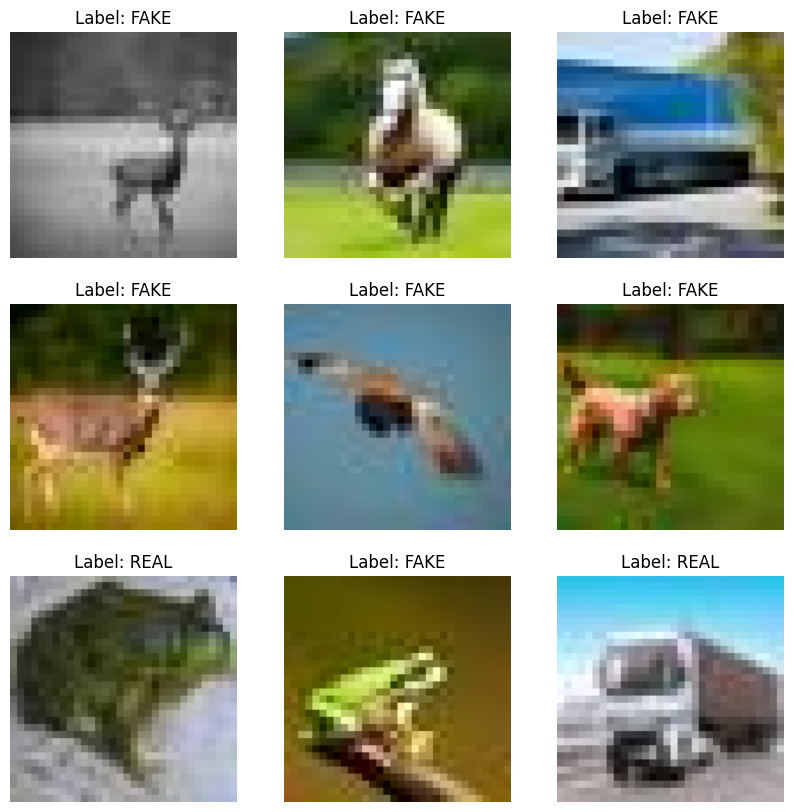

In [11]:
import matplotlib.pyplot as plt
import numpy as np

# Fetch a batch of images and labels
images, labels = next(train_generator)

# Define class names
class_names = {0: 'FAKE', 1: 'REAL'}

# Plot first 9 images
plt.figure(figsize=(10, 10))
for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(images[i])  # Display the image
    plt.title(f"Label: {class_names[int(labels[i])]}")
    plt.axis('off')
plt.show()

# ====================================
# 🏗️ 4. Model Building (Baseline)
# ====================================


In [12]:
base_model = ResNet50(weights='imagenet', include_top=False, input_shape=(128, 128, 3))
base_model.trainable = False

model = Sequential([
    base_model,
    GlobalAveragePooling2D(),
    Dropout(0.3),
    Dense(128, activation='relu'),
    Dense(1, activation='sigmoid')
])

model.compile(optimizer=Adam(learning_rate=1e-4), loss='binary_crossentropy', metrics=['accuracy'])




94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [13]:
history = model.fit(train_generator, validation_data=val_generator, epochs=5)
model.save('/kaggle/working/cifake_model.h5')

/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/5
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 558s 218ms/step - accuracy: 0.5916 - loss: 0.6672 - val_accuracy: 0.7102 - val_loss: 0.5984
Epoch 2/5
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 138s 55ms/step - accuracy: 0.6858 - loss: 0.6027 - val_accuracy: 0.7362 - val_loss: 0.5663
Epoch 3/5
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 142s 55ms/step - accuracy: 0.7086 - loss: 0.5749 - val_accuracy: 0.7195 - val_loss: 0.5492
Epoch 4/5
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 138s 55ms/step - accuracy: 0.7155 - loss: 0.5633 - val_accuracy: 0.7445 - val_loss: 0.5329
Epoch 5/5
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 119s 48ms/step - accuracy: 0.7189 - loss: 0.5584 - val_accuracy: 0.7566 - val_loss: 0.5263


In [14]:
# Save entire model
model.save('/content/drive/MyDrive/Colab Notebooks/output/cifake_model.h5')

# Save model architecture only (optional)
with open("/kaggle/working/model_architecture.json", "w") as json_file:
    json_file.write(model.to_json())

In [15]:
from tensorflow.keras.models import load_model

# Load saved model
model = load_model('/content/drive/MyDrive/Colab Notebooks/output/cifake_model.h5')


# ====================================
# 🔁 6. Model Fine-Tuning (Round 1)
# ====================================


In [16]:
model = load_model('/content/drive/MyDrive/Colab Notebooks/output/cifake_model.h5')
base_model = model.layers[0]
base_model.trainable = True

for layer in base_model.layers[:100]:
    layer.trainable = False

model.compile(optimizer=Adam(learning_rate=0.00001), loss='binary_crossentropy', metrics=['accuracy'])
history_fine_tune = model.fit(train_generator, validation_data=val_generator, epochs=5)
model.save('/content/drive/MyDrive/Colab Notebooks/output/cifake_model_finetuned.h5')

Epoch 1/5
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 242s 85ms/step - accuracy: 0.7692 - loss: 1.2167 - val_accuracy: 0.7771 - val_loss: 0.4826
Epoch 2/5
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 262s 90ms/step - accuracy: 0.8605 - loss: 0.3274 - val_accuracy: 0.7969 - val_loss: 0.4501
Epoch 3/5
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 207s 83ms/step - accuracy: 0.8745 - loss: 0.2974 - val_accuracy: 0.8841 - val_loss: 0.2731
Epoch 4/5
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 206s 82ms/step - accuracy: 0.8845 - loss: 0.2756 - val_accuracy: 0.8691 - val_loss: 0.3001
Epoch 5/5
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 206s 82ms/step - accuracy: 0.8883 - loss: 0.2632 - val_accuracy: 0.7977 - val_loss: 0.4706


# ====================================
# 🧠 7. Model Fine-Tuning (Round 2 - Improved)
# ====================================

In [17]:
model = load_model('/content/drive/MyDrive/Colab Notebooks/output/cifake_model.h5')
base_model = model.layers[0]
base_model.trainable = True

for layer in base_model.layers[:100]:
    layer.trainable = False

for layer in model.layers:
    if isinstance(layer, Dropout):
        layer.rate = 0.5

model.layers[-2] = Dense(128, activation='relu', kernel_regularizer=l2(0.01))

model.compile(optimizer=Adam(learning_rate=0.000005), loss='binary_crossentropy', metrics=['accuracy'])
early_stopping = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

In [18]:
history_fine_tune = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=10,
    callbacks=[early_stopping]
)

model.save('/content/drive/MyDrive/Colab Notebooks/output/cifake_model_finetuned_v2.h5')

Epoch 1/10
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 242s 86ms/step - accuracy: 0.7409 - loss: 1.8568 - val_accuracy: 0.8466 - val_loss: 0.3634
Epoch 2/10
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 207s 83ms/step - accuracy: 0.8487 - loss: 0.3533 - val_accuracy: 0.8481 - val_loss: 0.3410
Epoch 3/10
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 208s 83ms/step - accuracy: 0.8671 - loss: 0.3122 - val_accuracy: 0.8230 - val_loss: 0.3905
Epoch 4/10
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 208s 83ms/step - accuracy: 0.8826 - loss: 0.2825 - val_accuracy: 0.8407 - val_loss: 0.3683
Epoch 5/10
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 206s 83ms/step - accuracy: 0.8907 - loss: 0.2644 - val_accuracy: 0.8547 - val_loss: 0.3204
Epoch 6/10
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 215s 86ms/step - accuracy: 0.8943 - loss: 0.2530 - val_accuracy: 0.8846 - val_loss: 0.2835
Epoch 7/10
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 256s 84ms/step - accuracy: 0.9055 - loss: 0.2344 - val_accuracy: 0.8808 - val_loss: 0.2726
Epoch 8/10
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 210s 84ms/step - accuracy: 


# ====================================
# 📉 8. Training History Visualization
# ====================================

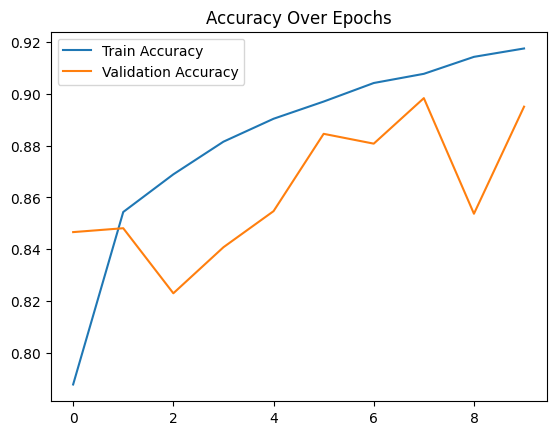

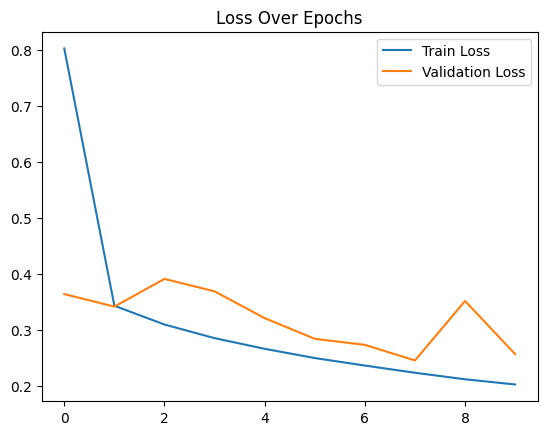

In [20]:
plt.figure()
plt.plot(history_fine_tune.history['accuracy'], label='Train Accuracy')
plt.plot(history_fine_tune.history['val_accuracy'], label='Validation Accuracy')
plt.title('Accuracy Over Epochs')
plt.legend()
plt.savefig("/content/drive/MyDrive/Colab Notebooks/Images/accuracy_curve.png")
plt.show()

plt.figure()
plt.plot(history_fine_tune.history['loss'], label='Train Loss')
plt.plot(history_fine_tune.history['val_loss'], label='Validation Loss')
plt.title('Loss Over Epochs')
plt.legend()
plt.savefig("/content/drive/MyDrive/Colab Notebooks/Images/loss_curve.png")
plt.show()



# ====================================
# 🧪 9. Model Evaluation
# ====================================

In [21]:
model_baseline = load_model('/content/drive/MyDrive/Colab Notebooks/output/cifake_model.h5')
model_finetuned = load_model('/content/drive/MyDrive/Colab Notebooks/output/cifake_model_finetuned.h5')
model_best_finetuned = load_model('/content/drive/MyDrive/Colab Notebooks/output/cifake_model_finetuned_v2.h5')


In [22]:
y_true = val_generator.classes
y_pred_baseline = model_baseline.predict(val_generator).flatten()
y_pred_finetuned = model_finetuned.predict(val_generator).flatten()
y_pred_best_finetuned = model_best_finetuned.predict(val_generator).flatten()

y_pred_baseline_bin = (y_pred_baseline > 0.5).astype(int)
y_pred_finetuned_bin = (y_pred_finetuned > 0.5).astype(int)
y_pred_best_finetuned_bin = (y_pred_best_finetuned > 0.5).astype(int)


625/625 ━━━━━━━━━━━━━━━━━━━━ 27s 38ms/step
625/625 ━━━━━━━━━━━━━━━━━━━━ 26s 37ms/step
625/625 ━━━━━━━━━━━━━━━━━━━━ 27s 37ms/step


In [23]:
def evaluate_model(y_true, y_pred, model_name, save_path=None):
    print(f"📊 Evaluation for {model_name}")
    print(f"Accuracy: {accuracy_score(y_true, y_pred):.4f}")
    print(f"Precision: {precision_score(y_true, y_pred):.4f}")
    print(f"Recall: {recall_score(y_true, y_pred):.4f}")
    print(f"F1-Score: {f1_score(y_true, y_pred):.4f}")
    print(f"AUC-ROC: {roc_auc_score(y_true, y_pred):.4f}")
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(5, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Fake', 'Real'], yticklabels=['Fake', 'Real'])
    plt.title(f'Confusion Matrix - {model_name}')
    if save_path:
        plt.savefig(f"{save_path}/confusion_matrix_{model_name}.png", bbox_inches='tight')
    plt.show()
    print(classification_report(y_true, y_pred, target_names=['Fake', 'Real']))



📊 Evaluation for Baseline Model
Accuracy: 0.4991
Precision: 0.4992
Recall: 0.5332
F1-Score: 0.5156
AUC-ROC: 0.4991


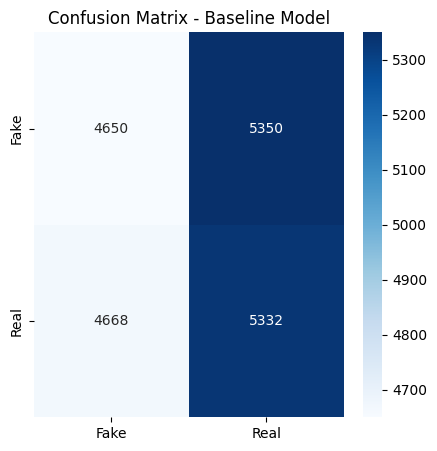

              precision    recall  f1-score   support

        Fake       0.50      0.47      0.48     10000
        Real       0.50      0.53      0.52     10000

    accuracy                           0.50     20000
   macro avg       0.50      0.50      0.50     20000
weighted avg       0.50      0.50      0.50     20000

📊 Evaluation for First Fine-Tuned Model
Accuracy: 0.4934
Precision: 0.4951
Recall: 0.6750
F1-Score: 0.5712
AUC-ROC: 0.4934


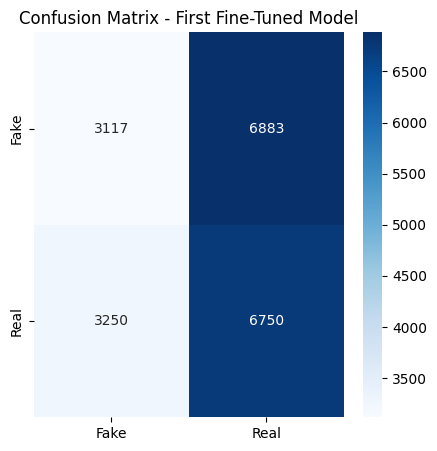

              precision    recall  f1-score   support

        Fake       0.49      0.31      0.38     10000
        Real       0.50      0.68      0.57     10000

    accuracy                           0.49     20000
   macro avg       0.49      0.49      0.48     20000
weighted avg       0.49      0.49      0.48     20000

📊 Evaluation for Best Fine-Tuned Model
Accuracy: 0.4986
Precision: 0.4985
Recall: 0.4811
F1-Score: 0.4897
AUC-ROC: 0.4986


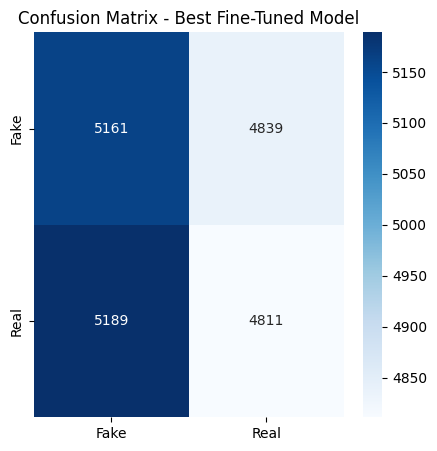

              precision    recall  f1-score   support

        Fake       0.50      0.52      0.51     10000
        Real       0.50      0.48      0.49     10000

    accuracy                           0.50     20000
   macro avg       0.50      0.50      0.50     20000
weighted avg       0.50      0.50      0.50     20000



In [24]:
image_save_path = "/content/drive/MyDrive/Colab Notebooks/images"
os.makedirs(image_save_path, exist_ok=True)

evaluate_model(y_true, y_pred_baseline_bin, "Baseline Model", save_path=image_save_path)
evaluate_model(y_true, y_pred_finetuned_bin, "First Fine-Tuned Model", save_path=image_save_path)
evaluate_model(y_true, y_pred_best_finetuned_bin, "Best Fine-Tuned Model", save_path=image_save_path)

# ====================================
# 📈 10. ROC Curve Comparison
# ====================================

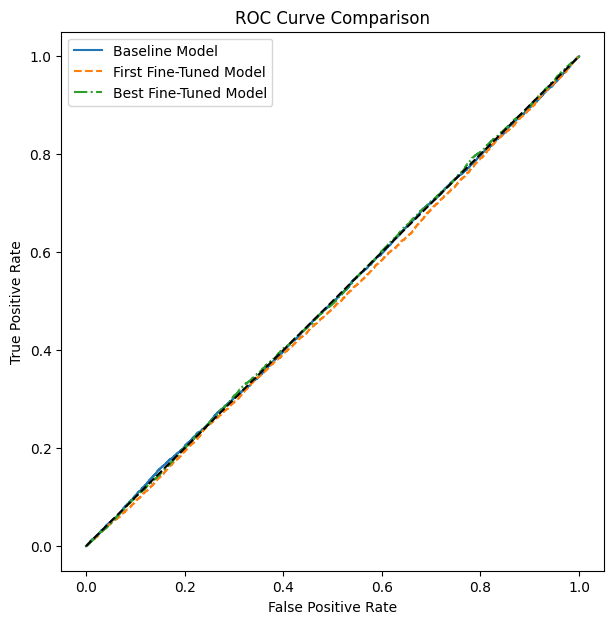

In [25]:
from sklearn.metrics import roc_curve

plt.figure(figsize=(7, 7))
fpr_base, tpr_base, _ = roc_curve(y_true, y_pred_baseline)
fpr_fine, tpr_fine, _ = roc_curve(y_true, y_pred_finetuned)
fpr_best, tpr_best, _ = roc_curve(y_true, y_pred_best_finetuned)

plt.plot(fpr_base, tpr_base, label='Baseline Model')
plt.plot(fpr_fine, tpr_fine, label='First Fine-Tuned Model', linestyle='--')
plt.plot(fpr_best, tpr_best, label='Best Fine-Tuned Model', linestyle='-.')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison')
plt.legend()
plt.savefig(os.path.join(image_save_path, "roc_curve_comparison.png"))
plt.show()

# ====================================
# 🌐 11. Model Deployment with Gradio
# ====================================


In [26]:
!pip install flask flask-ngrok
!pip install gradio

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 MB 21.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 322.2/322.2 kB 27.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 95.2/95.2 kB 9.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.5/11.5 MB 131.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.0/72.0 kB 7.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.5/62.5 kB 5.4 MB/s eta 0:00:00


In [31]:
import gradio as gr
from PIL import Image

import gradio as gr
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing import image
import numpy as np
from PIL import Image

model = load_model('/content/drive/MyDrive/Ai vs Human Images Detection /Model/cifake_model_finetuned_v2.h5')

def classify_image(img):
    img = img.resize((128, 128))
    img_array = image.img_to_array(img) / 255.0
    img_array = np.expand_dims(img_array, axis=0)
    prob = model.predict(img_array)[0][0]
    label = "Real" if prob >= 0.5 else "Fake"
    confidence = (prob if label == "Real" else 1 - prob) * 100
    return f"{label} ({confidence:.2f}%)"

# Gradio interface for multiple image upload
gr.Interface(
    fn=classify_image,
    inputs=gr.Image(type="pil", label="Upload an image"),
    outputs=gr.Textbox(label="Prediction"),
    allow_flagging="never",
    title="Real vs Fake Image Classifier"
).launch()


/usr/local/lib/python3.11/dist-packages/gradio/interface.py:415: UserWarning: The `allow_flagging` parameter in `Interface` is deprecated.Use `flagging_mode` instead.
  warnings.warn(


It looks like you are running Gradio on a hosted a Jupyter notebook. For the Gradio app to work, sharing must be enabled. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://de00b0a9bbc9dda6a9.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
from tensorflow.keras.preprocessing import image
import matplotlib.pyplot as plt
import numpy as np

# Path to your image
img_path = '/content/drive/MyDrive/your-folder-name/image.jpg'

# Load and preprocess image
img = image.load_img(img_path, target_size=(128, 128))
img_array = image.img_to_array(img) / 255.0
img_array = np.expand_dims(img_array, axis=0)

# Display the image
plt.imshow(img)
plt.title("Uploaded Image")
plt.axis('off')
plt.show()
